# Exercise 3: Decision Tree Classification

## Objective
Build a Decision Tree classifier to predict whether a bank customer subscribes to a term deposit.

## Key Techniques
- Gini vs. Entropy
- Train-test split with stratification
- Controlling overfitting
- Cost-complexity pruning
- Decision rule interpretation

## Evaluation
- Test accuracy
- Tree depth
- Classification report


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Project paths
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "bank_marketing.csv"

# Load dataset
df = pd.read_csv(DATA_PATH, sep=";")

# Prepare target
y = df["y"].astype(str).str.strip().str.lower().map({
    "no": 0,
    "yes": 1,
    "0": 0,
    "1": 1
})

if y.isna().any():
    raise ValueError("Unexpected values in target column: " + str(df["y"].unique()))

# Use available features
features = ["age", "job", "duration", "campaign", "poutcome"]
X = df[features]

if y.isna().any():
    raise ValueError("Target contains missing values. Check df['y'].")

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Preprocessing
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["job", "poutcome"]),
    ("num", "passthrough", ["age", "duration", "campaign"])
])

# Compare Gini and Entropy
gini_tree = Pipeline([
    ("prep", preprocessor),
    ("tree", DecisionTreeClassifier(criterion="gini", random_state=42))
])

entropy_tree = Pipeline([
    ("prep", preprocessor),
    ("tree", DecisionTreeClassifier(criterion="entropy", random_state=42))
])

gini_tree.fit(X_train, y_train)
entropy_tree.fit(X_train, y_train)

print("Dataset shape:", df.shape)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Gini training accuracy:", round(gini_tree.score(X_train, y_train), 4))
print("Gini test accuracy:", round(gini_tree.score(X_test, y_test), 4))
print("Entropy test accuracy:", round(entropy_tree.score(X_test, y_test), 4))
print("Unrestricted Gini depth:",
      gini_tree.named_steps["tree"].get_depth())

Dataset shape: (41188, 21)
Training rows: 30891
Testing rows: 10297
Gini training accuracy: 0.9977
Gini test accuracy: 0.8631
Entropy test accuracy: 0.8636
Unrestricted Gini depth: 33


In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Train a controlled Decision Tree
pruned_tree = Pipeline([
    ("prep", preprocessor),
    ("tree", DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42
    ))
])

pruned_tree.fit(X_train, y_train)

# Predict
y_pred = pruned_tree.predict(X_test)

# Evaluate
accuracy = accuracy_score(y_test, y_pred)
depth = pruned_tree.named_steps["tree"].get_depth()

print("Test Accuracy:", round(accuracy, 4))
print("Tree Depth:", depth)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Save predictions
PROJECT_ROOT.joinpath("outputs").mkdir(parents=True, exist_ok=True)

results = X_test.copy()
results["actual_y"] = y_test
results["predicted_y"] = y_pred

results.to_csv(
    PROJECT_ROOT / "outputs" / "exercise3_predictions.csv",
    index=False
)

print("\nSaved: outputs/exercise3_predictions.csv")
print("Accuracy target >= 0.85:", accuracy >= 0.85)
print("Depth target <= 5:", depth <= 5)

Test Accuracy: 0.9062
Tree Depth: 5

Classification Report:

              precision    recall  f1-score   support

           0       0.93      0.97      0.95      9137
           1       0.63      0.41      0.49      1160

    accuracy                           0.91     10297
   macro avg       0.78      0.69      0.72     10297
weighted avg       0.89      0.91      0.90     10297

Confusion Matrix:
 [[8858  279]
 [ 687  473]]

Saved: outputs/exercise3_predictions.csv
Accuracy target >= 0.85: True
Depth target <= 5: True


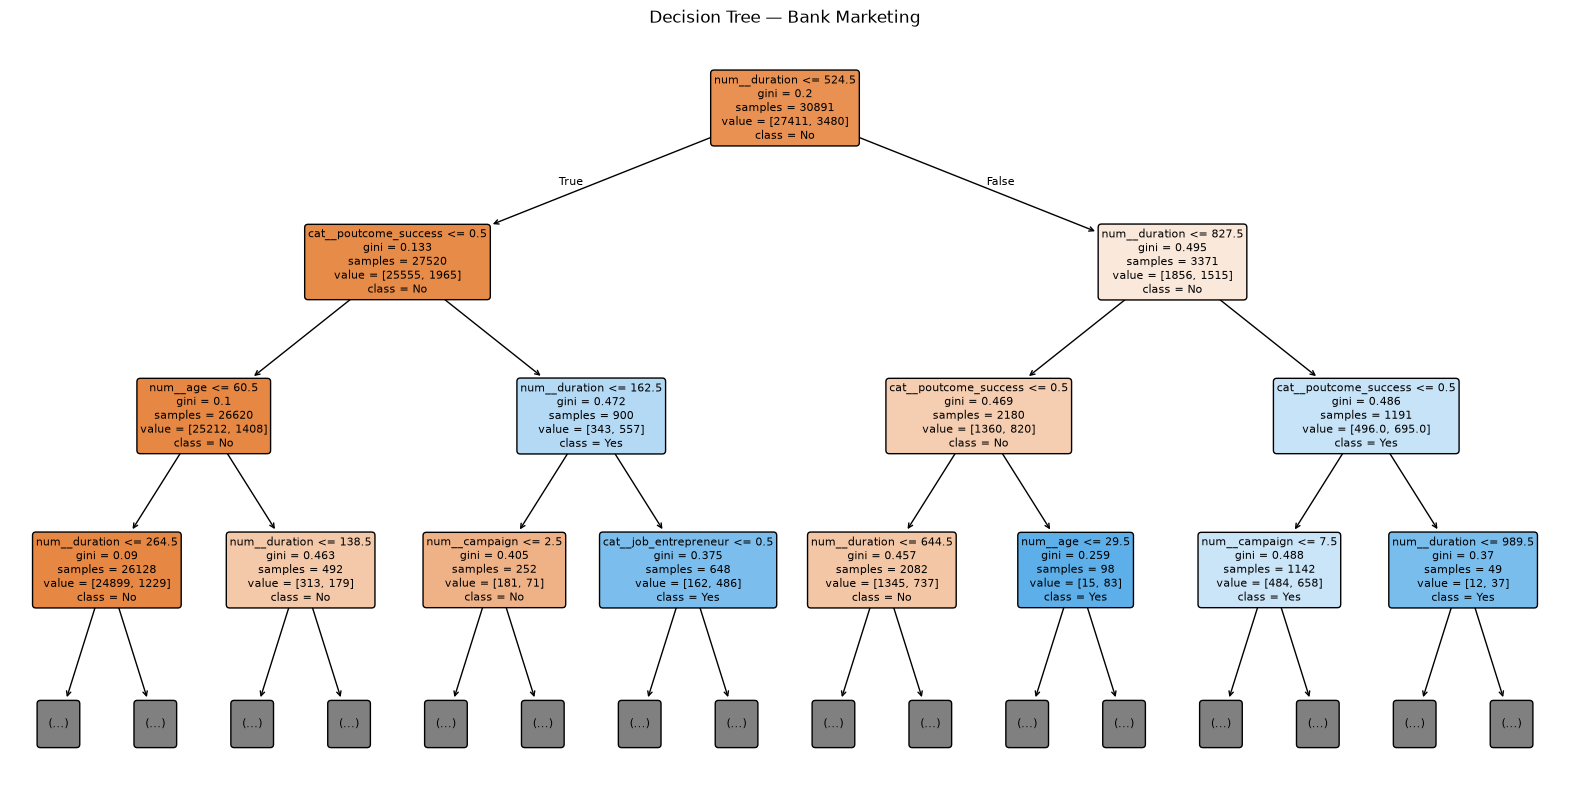

TOP DECISION RULES:

|--- num__duration <= 524.50
|   |--- cat__poutcome_success <= 0.50
|   |   |--- num__age <= 60.50
|   |   |   |--- num__duration <= 264.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- num__duration >  264.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- num__age >  60.50
|   |   |   |--- num__duration <= 138.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- num__duration >  138.50
|   |   |   |   |--- truncated branch of depth 2
|   |--- cat__poutcome_success >  0.50
|   |   |--- num__duration <= 162.50
|   |   |   |--- num__campaign <= 2.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- num__campaign >  2.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- num__duration >  162.50
|   |   |   |--- cat__job_entrepreneur <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- cat__job_entrepreneur >  0.50
|   |   |   |   |--- class: 0
|--- num__duration >  524.5

In [4]:
from sklearn.tree import plot_tree, export_text
import matplotlib.pyplot as plt

# Extract fitted tree and feature names
tree_model = pruned_tree.named_steps["tree"]
feature_names = pruned_tree.named_steps["prep"].get_feature_names_out()

# Visualize the decision tree
plt.figure(figsize=(20, 10))
plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=["No", "Yes"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree — Bank Marketing")
plt.show()

# Print decision rules
rules = export_text(
    tree_model,
    feature_names=list(feature_names),
    max_depth=3
)
print("TOP DECISION RULES:\n")
print(rules)

# Verify prediction file exists
prediction_file = PROJECT_ROOT / "outputs" / "exercise3_predictions.csv"
print("\nPrediction file exists:", prediction_file.exists())

# Final summary
print("\n===== EXERCISE 3 SUMMARY =====")
print("Test accuracy:", round(accuracy, 4))
print("Tree depth:", tree_model.get_depth())
print("Accuracy target (>= 0.85):", accuracy >= 0.85)
print("Depth target (<= 5):", tree_model.get_depth() <= 5)